In [2]:
!wget https://files.grouplens.org/datasets/movielens/ml-latest-small.zip


--2026-11-23 11:54:09--  https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.96.204
Connecting to files.grouplens.org (files.grouplens.org)|128.101.96.204|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 978202 (955K) [application/zip]
Saving to: ‘ml-latest-small.zip’

ml-latest-small.zip 100%[===================>] 955.28K  3.28MB/s    in 0.3s    

2026-11-23 11:54:10 (3.28 MB/s) - ‘ml-latest-small.zip’ saved [978202/978202]



In [3]:
!unzip -q ml-latest-small.zip -d data

In [4]:
import os

os.listdir("data/ml-latest-small")

['tags.csv', 'movies.csv', 'ratings.csv', 'links.csv', 'README.txt']

In [5]:
import pandas as pd

In [12]:
import pandas as pd

ratings = pd.read_csv("data/ml-latest-small/ratings.csv")
movies = pd.read_csv("data/ml-latest-small/movies.csv")

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


In [13]:
# PHASE 1 - STEP 1.1
# Create SQLite database and tables

import sqlite3

conn = sqlite3.connect("movielens.db")

ratings.to_sql(
    "ratings",
    conn,
    if_exists="replace",
    index=False
)

movies.to_sql(
    "movies",
    conn,
    if_exists="replace",
    index=False
)

print("Database and tables created successfully!")

Database and tables created successfully!


In [14]:
# PHASE 1 - STEP 1.1 (Verification)

cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")

print(cursor.fetchall())

[('ratings',), ('movies',)]


In [15]:
# PHASE 1 - STEP 1.2
# Basic dataset statistics

query = """
SELECT
    COUNT(DISTINCT userId) AS total_users,
    COUNT(DISTINCT movieId) AS total_movies,
    COUNT(*) AS total_ratings
FROM ratings;
"""

basic_stats = pd.read_sql_query(query, conn)

display(basic_stats)

,total_users,total_movies,total_ratings
0,610,9724,100836


In [16]:
# PHASE 1 - STEP 1.2
# Query 2: Calculate matrix density and sparsity

total_users = 610
total_movies = 9724
total_ratings = 100836

total_possible_ratings = total_users * total_movies

density = total_ratings / total_possible_ratings
sparsity = 1 - density

print("Matrix Density:", round(density * 100, 2), "%")
print("Matrix Sparsity:", round(sparsity * 100, 2), "%")

Matrix Density: 1.7 %
Matrix Sparsity: 98.3 %


In [17]:
# PHASE 1 - STEP 1.2
# Query 3: Top 10 most-rated movies

query = """
SELECT
    m.title,
    COUNT(*) AS number_of_ratings,
    ROUND(AVG(r.rating), 2) AS average_rating
FROM ratings r
JOIN movies m
    ON r.movieId = m.movieId
GROUP BY m.movieId
ORDER BY number_of_ratings DESC
LIMIT 10;
"""

top_movies = pd.read_sql_query(query, conn)

display(top_movies)

,title,number_of_ratings,average_rating
0,Forrest Gump (1994),329,4.16
1,"Shawshank Redemption, The (1994)",317,4.43
2,Pulp Fiction (1994),307,4.20
3,"Silence of the Lambs, The (1991)",279,4.16
4,"Matrix, The (1999)",278,4.19
5,Star Wars: Episode IV - A New Hope (1977),251,4.23
6,Jurassic Park (1993),238,3.75
7,Braveheart (1995),237,4.03
8,Terminator 2: Judgment Day (1991),224,3.97
9,Schindler's List (1993),220,4.22


In [18]:
# PHASE 1 - STEP 1.2
# Query 4: Users with the fewest ratings

query = """
SELECT
    userId,
    COUNT(*) AS number_of_ratings
FROM ratings
GROUP BY userId
ORDER BY number_of_ratings ASC
LIMIT 10;
"""

least_active_users = pd.read_sql_query(query, conn)

display(least_active_users)

,userId,number_of_ratings
0,53,20
1,147,20
2,189,20
3,194,20
4,207,20
5,257,20
6,278,20
7,320,20
8,406,20
9,431,20


In [19]:
# PHASE 1 - STEP 1.2
# Query 5: Rating distribution

query = """
SELECT
    rating,
    COUNT(*) AS number_of_ratings
FROM ratings
GROUP BY rating
ORDER BY rating ASC;
"""

rating_distribution = pd.read_sql_query(query, conn)

display(rating_distribution)

,rating,number_of_ratings
0,0.5,1370
1,1.0,2811
2,1.5,1791
3,2.0,7551
4,2.5,5550
5,3.0,20047
6,3.5,13136
7,4.0,26818
8,4.5,8551
9,5.0,13211


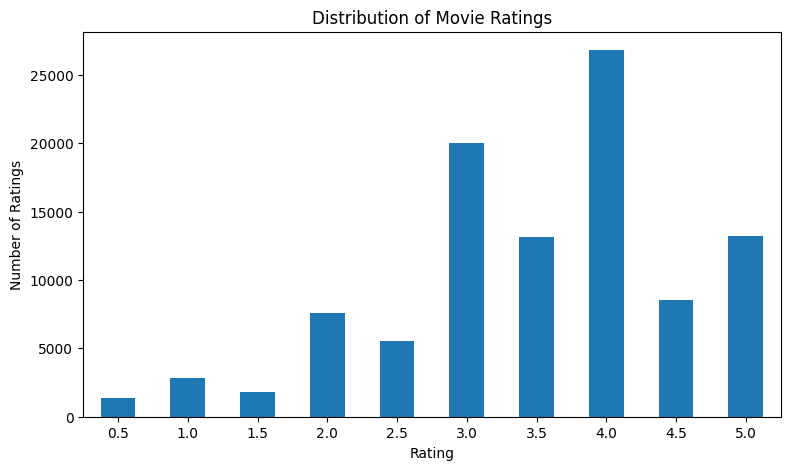

In [20]:
# PHASE 1 - STEP 1.3.1
# Visualise rating distribution

import matplotlib.pyplot as plt

ratings['rating'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()

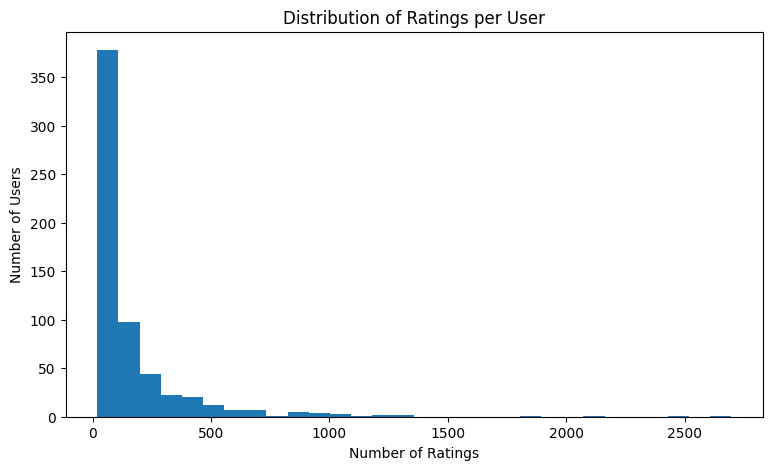

In [21]:
# PHASE 1 - STEP 1.3.2
# Distribution of ratings per user

ratings_per_user = ratings.groupby('userId')['rating'].count()

plt.figure(figsize=(9, 5))
plt.hist(ratings_per_user, bins=30)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

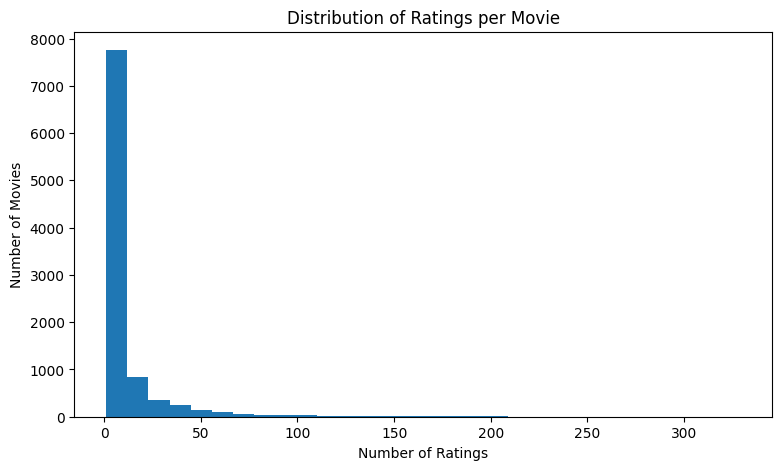

In [22]:
# PHASE 1 - STEP 1.3.3
# Distribution of ratings per movie

ratings_per_movie = ratings.groupby('movieId')['rating'].count()

plt.figure(figsize=(9, 5))
plt.hist(ratings_per_movie, bins=30)

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")
plt.show()

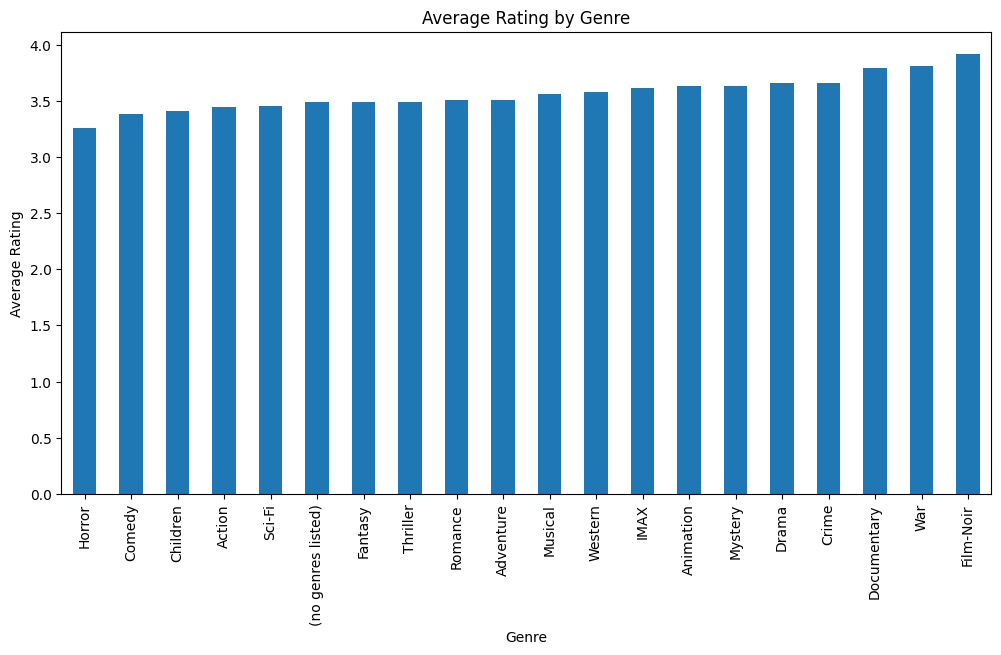

In [23]:
# PHASE 1 - STEP 1.3.4
# Average rating by genre

movie_ratings = pd.merge(
    ratings,
    movies,
    on='movieId'
)

genre_ratings = movie_ratings.assign(
    genres=movie_ratings['genres'].str.split('|')
).explode('genres')

avg_genre_rating = genre_ratings.groupby(
    'genres'
)['rating'].mean()

avg_genre_rating.sort_values().plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.show()

User-Item Matrix

In [24]:
# PHASE 1 - STEP 1.4
# Create the User-Item Matrix

user_item = ratings.pivot_table(
    index='userId',
    columns='movieId',
    values='rating'
)

print("User-Item Matrix Shape:", user_item.shape)

display(user_item.head())

User-Item Matrix Shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
# PHASE 1 - STEP 1.5
# Split ratings into training and testing data

np.random.seed(42)

def train_test_split_ratings(ratings_df, test_frac=0.2):
    test_idx = (
        ratings_df.groupby('userId')
        .apply(lambda g: g.sample(
            frac=test_frac,
            random_state=42
        ).index)
        .explode()
        .dropna()
    )

    test = ratings_df.loc[test_idx]
    train = ratings_df.drop(test_idx)

    return train, test


train_ratings, test_ratings = train_test_split_ratings(ratings)

print("Original ratings:", len(ratings))
print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))

Original ratings: 100836
Training ratings: 80672
Testing ratings: 20164


/tmp/ipykernel_473/3100286273.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(


USER USER CF

In [26]:
# PHASE 2 - STEP 2.1
# Create the Training User-Item Matrix

train_matrix = train_ratings.pivot_table(
    index='userId',
    columns='movieId',
    values='rating'
)

print("Training Matrix Shape:", train_matrix.shape)

display(train_matrix.head())

Training Matrix Shape: (610, 8970)


movieId,1,2,3,4,5,6,7,8,9,10,...,191005,193565,193567,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# PHASE 2 - STEP 2.2
# Fill missing ratings with 0

train_matrix_filled = train_matrix.fillna(0)

print("Missing values before:", train_matrix.isna().sum().sum())
print("Missing values after:", train_matrix_filled.isna().sum().sum())

display(train_matrix_filled.head())

Missing values before: 5391028
Missing values after: 0


movieId,1,2,3,4,5,6,7,8,9,10,...,191005,193565,193567,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


cosine similarity

In [28]:
# PHASE 2 - STEP 2.3
# Calculate User-User Cosine Similarity

from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(train_matrix_filled)

print("User Similarity Matrix Shape:", user_similarity.shape)

display(pd.DataFrame(
    user_similarity,
    index=train_matrix_filled.index,
    columns=train_matrix_filled.index
).head())

User Similarity Matrix Shape: (610, 610)


userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
userId,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.000000,0.077062,0.131753,0.099249,0.125053,0.129594,0.107647,0.048238,0.009606,...,0.055346,0.106007,0.180162,0.067435,0.127853,0.136004,0.231661,0.240803,0.073003,0.134585
2,0.000000,1.000000,0.000000,0.000000,0.021936,0.033434,0.027730,0.035452,0.000000,0.025923,...,0.212028,0.022625,0.015860,0.000000,0.000000,0.021944,0.000000,0.052211,0.036763,0.082222
3,0.077062,0.000000,1.000000,0.000000,0.006459,0.005063,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.002398,0.029349,0.000000,0.000000,0.013645,0.024798,0.027249,0.000000,0.034341
4,0.131753,0.000000,0.000000,1.000000,0.127372,0.100189,0.068789,0.053178,0.014041,0.024728,...,0.073741,0.103457,0.235686,0.050786,0.077247,0.147172,0.118446,0.120987,0.035578,0.079219
5,0.099249,0.021936,0.006459,0.127372,1.000000,0.261289,0.089153,0.271282,0.000000,0.037985,...,0.038725,0.292236,0.111600,0.190331,0.106363,0.078840,0.110551,0.110481,0.152132,0.058385


In [29]:
# PHASE 2 - STEP 2.4
# Find the Top 20 Similar Users for User 1

user_id = 1

similar_users = pd.Series(
    user_similarity[
        train_matrix_filled.index.get_loc(user_id)
    ],
    index=train_matrix_filled.index
)

# Remove User 1 from the results
similar_users = similar_users.drop(user_id)

# Select the 20 most similar users
top_20_users = similar_users.sort_values(
    ascending=False
).head(20)

print("Top 20 Similar Users for User 1:")
display(top_20_users)

Top 20 Similar Users for User 1:


,0
userId,
368,0.305865
266,0.296444
57,0.295724
313,0.291599
330,0.285331
91,0.278911
45,0.271276
480,0.270389
597,0.265919


In [30]:
# PHASE 2 - STEP 2.5
# Create the User-User Rating Prediction Function

def predict_user_rating(user_id, movie_id, top_users):

    numerator = 0
    denominator = 0

    for other_user, similarity in top_users.items():

        rating = train_matrix.loc[other_user, movie_id]

        if pd.notna(rating):
            numerator += similarity * rating
            denominator += abs(similarity)

    if denominator == 0:
        return np.nan

    return numerator / denominator

In [31]:
# PHASE 2 - STEP 2.6
# Create the User-User Movie Recommendation Function

def recommend_movies(user_id, top_users, n_recommendations=10):

    unrated_movies = train_matrix.loc[user_id][
        train_matrix.loc[user_id].isna()
    ].index

    predictions = []

    for movie_id in unrated_movies:

        predicted_rating = predict_user_rating(
            user_id,
            movie_id,
            top_users
        )

        if pd.notna(predicted_rating):

            neighbour_count = sum(
                pd.notna(train_matrix.loc[other_user, movie_id])
                for other_user in top_users.index
            )

            predictions.append((
                movie_id,
                predicted_rating,
                neighbour_count
            ))

    predictions.sort(key=lambda x: x[1], reverse=True)

    recommendations_df = pd.DataFrame(
        predictions,
        columns=[
            'movieId',
            'predicted_rating',
            'neighbour_count'
        ]
    )

    recommendations_df = recommendations_df.merge(
        movies[['movieId', 'title']],
        on='movieId',
        how='left'
    )

    return recommendations_df[
        ['movieId', 'title', 'predicted_rating', 'neighbour_count']
    ].head(n_recommendations)

In [32]:
# PHASE 2 - STEP 2.7
# Generate User-User Recommendations for User 1

user_user_recommendations = recommend_movies(
    user_id=1,
    top_users=top_20_users,
    n_recommendations=10
)

display(user_user_recommendations)

,movieId,title,predicted_rating,neighbour_count
0,232,Eat Drink Man Woman (Yin shi nan nu) (1994),5.0,1
1,281,Nobody's Fool (1994),5.0,1
2,306,Three Colors: Red (Trois couleurs: Rouge) (1994),5.0,1
3,348,Bullets Over Broadway (1994),5.0,2
4,456,Fresh (1994),5.0,1
5,514,"Ref, The (1994)",5.0,1
6,1081,Victor/Victoria (1982),5.0,1
7,1095,Glengarry Glen Ross (1992),5.0,1
8,1104,"Streetcar Named Desire, A (1951)",5.0,1
9,1147,When We Were Kings (1996),5.0,1


In [33]:
# PHASE 2 - STEP 2.8
# Analyse Neighbour Support

print("Neighbour Support Distribution:")

display(
    user_user_recommendations['neighbour_count']
    .value_counts()
    .sort_index()
)

Neighbour Support Distribution:


,count
neighbour_count,
1,9
2,1


In [34]:
# PHASE 2 - STEP 2.9
# Filter recommendations by minimum neighbour support

reliable_recommendations = user_user_recommendations[
    user_user_recommendations['neighbour_count'] >= 2
]

print("Recommendations with at least 2 neighbours:")
display(reliable_recommendations)

Recommendations with at least 2 neighbours:


,movieId,title,predicted_rating,neighbour_count
3,348,Bullets Over Broadway (1994),5.0,2


Increase the Number of Neighbours

In [35]:
# PHASE 2 - STEP 2.10
# Find the Top 50 Similar Users for User 1

top_50_users = similar_users.sort_values(
    ascending=False
).head(50)

print("Number of neighbours:", len(top_50_users))

user_user_recommendations_50 = recommend_movies(
    user_id=1,
    top_users=top_50_users,
    n_recommendations=10
)

display(user_user_recommendations_50)

Number of neighbours: 50


,movieId,title,predicted_rating,neighbour_count
0,3814,Love and Death (1975),5.0,2
1,85,Angels and Insects (1995),5.0,1
2,187,Party Girl (1995),5.0,1
3,290,Once Were Warriors (1994),5.0,1
4,456,Fresh (1994),5.0,1
5,599,"Wild Bunch, The (1969)",5.0,1
6,633,Denise Calls Up (1995),5.0,1
7,1147,When We Were Kings (1996),5.0,1
8,1150,"Return of Martin Guerre, The (Retour de Martin...",5.0,1
9,1178,Paths of Glory (1957),5.0,4


In [36]:
# PHASE 2 - STEP 2.11
# Filter Top 50 recommendations by neighbour support

reliable_recommendations_50 = user_user_recommendations_50[
    user_user_recommendations_50['neighbour_count'] >= 2
]

print("Reliable recommendations using Top 50 neighbours:")
display(reliable_recommendations_50)

Reliable recommendations using Top 50 neighbours:


,movieId,title,predicted_rating,neighbour_count
0,3814,Love and Death (1975),5.0,2
9,1178,Paths of Glory (1957),5.0,4


Evaluation of user user cf

In [37]:
# PHASE 2 - STEP 2.12
# Create Precision@K and Recall@K Evaluation Function

def precision_recall_at_k(recommended_movies, relevant_movies, k=10):

    recommended_k = recommended_movies[:k]

    if len(recommended_k) == 0:
        return 0, 0

    relevant_recommended = len(
        set(recommended_k) & set(relevant_movies)
    )

    precision = relevant_recommended / k

    recall = (
        relevant_recommended / len(relevant_movies)
        if len(relevant_movies) > 0
        else 0
    )

    return precision, recall

In [38]:
# PHASE 2 - STEP 2.13
# Evaluate User-User CF across all users

precision_scores = []
recall_scores = []

for user_id in train_matrix.index:

    # Find this user's relevant movies in the test set
    relevant_movies = test_ratings[
        (test_ratings['userId'] == user_id) &
        (test_ratings['rating'] >= 4.0)
    ]['movieId'].tolist()

    if len(relevant_movies) == 0:
        continue

    # Find the user's 20 most similar neighbours
    user_index = train_matrix_filled.index.get_loc(user_id)

    similar_users = pd.Series(
        user_similarity[user_index],
        index=train_matrix_filled.index
    ).drop(user_id)

    top_users = similar_users.sort_values(
        ascending=False
    ).head(20)

    # Generate recommendations
    recommendations = recommend_movies(
        user_id=user_id,
        top_users=top_users,
        n_recommendations=10
    )

    recommended_movie_ids = recommendations['movieId'].tolist()

    # Calculate Precision@10 and Recall@10
    precision, recall = precision_recall_at_k(
        recommended_movie_ids,
        relevant_movies,
        k=10
    )

    precision_scores.append(precision)
    recall_scores.append(recall)

# Calculate average metrics
print("User-User Collaborative Filtering Results")
print("------------------------------------------")
print("Evaluated users:", len(precision_scores))
print("Average Precision@10:", round(np.mean(precision_scores), 4))
print("Average Recall@10:", round(np.mean(recall_scores), 4))

User-User Collaborative Filtering Results
------------------------------------------
Evaluated users: 600
Average Precision@10: 0.0108
Average Recall@10: 0.014


ITEM User matrix

In [39]:
# PHASE 3 - STEP 3.1
# Create the Item-User Matrix

item_matrix = train_matrix_filled.T

print("Item-User Matrix Shape:", item_matrix.shape)

display(item_matrix.head())

Item-User Matrix Shape: (8970, 610)


userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,0.0,4.0,0.0,4.5,0.0,0.0,0.0,...,0.0,0.0,4.0,0.0,4.0,2.5,4.0,2.5,3.0,5.0
2,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,...,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0,0.0
3,4.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


In [40]:
# PHASE 3 - STEP 3.2
# Calculate Item-Item Cosine Similarity

item_similarity = cosine_similarity(item_matrix)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_matrix.index,
    columns=item_matrix.index
)

print("Item Similarity Matrix Shape:", item_similarity_df.shape)

display(item_similarity_df.iloc[:5, :5])

Item Similarity Matrix Shape: (8970, 8970)


movieId,1,2,3,4,5
movieId,,,,,
1,1.000000,0.365815,0.221266,0.000000,0.248851
2,0.365815,1.000000,0.242198,0.093342,0.243236
3,0.221266,0.242198,1.000000,0.114474,0.408487
4,0.000000,0.093342,0.114474,1.000000,0.070429
5,0.248851,0.243236,0.408487,0.070429,1.000000


In [41]:
# PHASE 3 - STEP 3.3
# Find movies similar to Toy Story (1995)

movie_id = 1

similar_movies = item_similarity_df[movie_id].drop(movie_id)

top_5_similar_movies = similar_movies.sort_values(
    ascending=False
).head(5)

similar_movie_results = pd.DataFrame({
    'movieId': top_5_similar_movies.index,
    'similarity': top_5_similar_movies.values
})

similar_movie_results = similar_movie_results.merge(
    movies[['movieId', 'title']],
    on='movieId',
    how='left'
)

display(
    similar_movie_results[
        ['movieId', 'title', 'similarity']
    ]
)

,movieId,title,similarity
0,260,Star Wars: Episode IV - A New Hope (1977),0.457954
1,588,Aladdin (1992),0.438634
2,780,Independence Day (a.k.a. ID4) (1996),0.427145
3,1270,Back to the Future (1985),0.423067
4,1210,Star Wars: Episode VI - Return of the Jedi (1983),0.418910


In [42]:
# PHASE 3 - STEP 3.4
# Item-Item Collaborative Filtering Recommendation Function

def recommend_item_item_v4(user_id, n_recommendations=10):

    user_ratings = train_matrix.loc[user_id].dropna()

    weighted_scores = {}
    similarity_sums = {}
    contribution_counts = {}

    for rated_movie, rating in user_ratings.items():

        similar_movies = item_similarity_df[rated_movie].sort_values(
            ascending=False
        )

        for candidate_movie, similarity in similar_movies.items():

            if candidate_movie in user_ratings.index:
                continue

            if similarity <= 0:
                continue

            weighted_scores[candidate_movie] = (
                weighted_scores.get(candidate_movie, 0)
                + similarity * rating
            )

            similarity_sums[candidate_movie] = (
                similarity_sums.get(candidate_movie, 0)
                + similarity
            )

            contribution_counts[candidate_movie] = (
                contribution_counts.get(candidate_movie, 0) + 1
            )

    recommendations = []

    for movie_id in weighted_scores:

        if contribution_counts[movie_id] < 5:
            continue

        predicted_rating = (
            weighted_scores[movie_id] / similarity_sums[movie_id]
        )

        recommendations.append((
            movie_id,
            predicted_rating,
            contribution_counts[movie_id]
        ))

    recommendations.sort(key=lambda x: x[1], reverse=True)

    recommendations_df = pd.DataFrame(
        recommendations,
        columns=[
            'movieId',
            'predicted_rating',
            'contributing_movies'
        ]
    )

    recommendations_df = recommendations_df.merge(
        movies[['movieId', 'title']],
        on='movieId',
        how='left'
    )

    return recommendations_df[
        [
            'movieId',
            'title',
            'predicted_rating',
            'contributing_movies'
        ]
    ].head(n_recommendations)

In [43]:
# PHASE 3 - STEP 3.4
# Generate Item-Item Recommendations for User 1

item_item_recommendations = recommend_item_item_v4(
    user_id=1,
    n_recommendations=10
)

display(item_item_recommendations)

,movieId,title,predicted_rating,contributing_movies
0,130842,Power/Rangers (2015),5.000000,7
1,132888,Comedy Central Roast of James Franco (2013),5.000000,7
2,159441,The Do-Over (2016),5.000000,7
3,113604,If I Stay (2014),5.000000,7
4,112897,The Expendables 3 (2014),5.000000,7
5,145935,"Peanuts Movie, The (2015)",5.000000,7
6,96964,"Tall Man, The (2012)",5.000000,7
7,114494,Who Am I (Kein System Ist Sicher) (2014),5.000000,7
8,132800,Welcome to Me (2014),4.987440,13
9,96608,Runaway Brain (1995),4.981774,6


Evaluate Item-Item Model

In [44]:
# PHASE 3 - STEP 3.5
# Evaluate Item-Item Collaborative Filtering

item_precision_scores = []
item_recall_scores = []

for user_id in train_matrix.index:

    relevant_movies = test_ratings[
        (test_ratings['userId'] == user_id) &
        (test_ratings['rating'] >= 4.0)
    ]['movieId'].tolist()

    if len(relevant_movies) == 0:
        continue

    recommendations = recommend_item_item_v4(
        user_id=user_id,
        n_recommendations=10
    )

    recommended_movie_ids = recommendations['movieId'].tolist()

    precision, recall = precision_recall_at_k(
        recommended_movie_ids,
        relevant_movies,
        k=10
    )

    item_precision_scores.append(precision)
    item_recall_scores.append(recall)

print("Evaluated users:", len(item_precision_scores))
print("Item-Item Precision@10:", round(np.mean(item_precision_scores), 4))
print("Item-Item Recall@10:", round(np.mean(item_recall_scores), 4))

Evaluated users: 600
Item-Item Precision@10: 0.0002
Item-Item Recall@10: 0.0


Matrix Factorization

In [45]:
# PHASE 4 - STEP 4.1
# Create User and Movie ID Mappings

user_ids = train_ratings['userId'].unique()
movie_ids = train_ratings['movieId'].unique()

user_to_idx = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

movie_to_idx = {
    movie_id: index
    for index, movie_id in enumerate(movie_ids)
}

idx_to_movie = {
    index: movie_id
    for movie_id, index in movie_to_idx.items()
}

mf_train = train_ratings.copy()

mf_train['user_idx'] = mf_train['userId'].map(user_to_idx)
mf_train['movie_idx'] = mf_train['movieId'].map(movie_to_idx)

print("Number of users:", len(user_to_idx))
print("Number of movies:", len(movie_to_idx))
print("Training records:", len(mf_train))

display(mf_train.head())

Number of users: 610
Number of movies: 8970
Training records: 80672


,userId,movieId,rating,timestamp,user_idx,movie_idx
0,1,1,4.0,964982703,0,0
1,1,3,4.0,964981247,0,1
2,1,6,4.0,964982224,0,2
3,1,47,5.0,964983815,0,3
4,1,50,5.0,964982931,0,4


In [46]:
# PHASE 4 - STEP 4.2
# Initialize Matrix Factorization Parameters

n_users = len(user_to_idx)
n_movies = len(movie_to_idx)
n_factors = 20

np.random.seed(42)

P = np.random.normal(
    scale=0.1,
    size=(n_users, n_factors)
)

Q = np.random.normal(
    scale=0.1,
    size=(n_movies, n_factors)
)

user_bias = np.zeros(n_users)
movie_bias = np.zeros(n_movies)

global_mean = mf_train['rating'].mean()

print("P shape:", P.shape)
print("Q shape:", Q.shape)
print("User bias shape:", user_bias.shape)
print("Movie bias shape:", movie_bias.shape)
print("Global mean rating:", round(global_mean, 4))

P shape: (610, 20)
Q shape: (8970, 20)
User bias shape: (610,)
Movie bias shape: (8970,)
Global mean rating: 3.5037


In [47]:
# PHASE 4 - STEP 4.3
# Train Matrix Factorization using Stochastic Gradient Descent

learning_rate = 0.005
regularization = 0.02
epochs = 20

train_rmse_history = []

for epoch in range(epochs):

    shuffled_data = mf_train.sample(
        frac=1,
        random_state=epoch
    )

    total_squared_error = 0

    for row in shuffled_data.itertuples(index=False):

        u = user_to_idx[row.userId]
        m = movie_to_idx[row.movieId]
        actual_rating = row.rating

        predicted_rating = (
            global_mean
            + user_bias[u]
            + movie_bias[m]
            + np.dot(P[u], Q[m])
        )

        error = actual_rating - predicted_rating

        total_squared_error += error ** 2

        P_old = P[u].copy()
        Q_old = Q[m].copy()

        user_bias[u] += learning_rate * (
            error - regularization * user_bias[u]
        )

        movie_bias[m] += learning_rate * (
            error - regularization * movie_bias[m]
        )

        P[u] += learning_rate * (
            error * Q_old - regularization * P_old
        )

        Q[m] += learning_rate * (
            error * P_old - regularization * Q_old
        )

    rmse = np.sqrt(total_squared_error / len(shuffled_data))
    train_rmse_history.append(rmse)

    print(f"Epoch {epoch + 1}/{epochs} - Train RMSE: {rmse:.4f}")

Epoch 1/20 - Train RMSE: 0.9644
Epoch 2/20 - Train RMSE: 0.9125
Epoch 3/20 - Train RMSE: 0.8921
Epoch 4/20 - Train RMSE: 0.8790
Epoch 5/20 - Train RMSE: 0.8692
Epoch 6/20 - Train RMSE: 0.8612
Epoch 7/20 - Train RMSE: 0.8543
Epoch 8/20 - Train RMSE: 0.8481
Epoch 9/20 - Train RMSE: 0.8426
Epoch 10/20 - Train RMSE: 0.8372
Epoch 11/20 - Train RMSE: 0.8320
Epoch 12/20 - Train RMSE: 0.8269
Epoch 13/20 - Train RMSE: 0.8218
Epoch 14/20 - Train RMSE: 0.8165
Epoch 15/20 - Train RMSE: 0.8111
Epoch 16/20 - Train RMSE: 0.8056
Epoch 17/20 - Train RMSE: 0.7997
Epoch 18/20 - Train RMSE: 0.7935
Epoch 19/20 - Train RMSE: 0.7870
Epoch 20/20 - Train RMSE: 0.7802


In [48]:
# PHASE 4 - STEP 4.4
# Evaluate Matrix Factorization on Test Data

test_predictions = []
actual_ratings = []

for row in test_ratings.itertuples(index=False):

    user_id = row.userId
    movie_id = row.movieId
    actual_rating = row.rating

    # Skip users or movies not present in training mappings
    if user_id not in user_to_idx or movie_id not in movie_to_idx:
        continue

    u = user_to_idx[user_id]
    m = movie_to_idx[movie_id]

    predicted_rating = (
        global_mean
        + user_bias[u]
        + movie_bias[m]
        + np.dot(P[u], Q[m])
    )

    # Keep predictions within the MovieLens rating scale
    predicted_rating = np.clip(predicted_rating, 0.5, 5.0)

    test_predictions.append(predicted_rating)
    actual_ratings.append(actual_rating)

rmse = np.sqrt(
    np.mean((np.array(actual_ratings) - np.array(test_predictions)) ** 2)
)

mae = np.mean(
    np.abs(np.array(actual_ratings) - np.array(test_predictions))
)

print("Evaluated test ratings:", len(test_predictions))
print("Test RMSE:", round(rmse, 4))
print("Test MAE:", round(mae, 4))

Evaluated test ratings: 19344
Test RMSE: 0.8664
Test MAE: 0.6653


In [49]:
# PHASE 4 - STEP 4.5
# Matrix Factorization Recommendation Function

def recommend_matrix_factorization(user_id, n_recommendations=10):

    if user_id not in user_to_idx:
        return pd.DataFrame()

    u = user_to_idx[user_id]

    rated_movies = set(
        train_ratings[
            train_ratings['userId'] == user_id
        ]['movieId']
    )

    recommendations = []

    for movie_id, m in movie_to_idx.items():

        if movie_id in rated_movies:
            continue

        predicted_rating = (
            global_mean
            + user_bias[u]
            + movie_bias[m]
            + np.dot(P[u], Q[m])
        )

        predicted_rating = np.clip(
            predicted_rating, 0.5, 5.0
        )

        recommendations.append((
            movie_id,
            predicted_rating
        ))

    recommendations.sort(
        key=lambda x: x[1],
        reverse=True
    )

    recommendations_df = pd.DataFrame(
        recommendations,
        columns=['movieId', 'predicted_rating']
    )

    recommendations_df = recommendations_df.merge(
        movies[['movieId', 'title']],
        on='movieId',
        how='left'
    )

    return recommendations_df[
        ['movieId', 'title', 'predicted_rating']
    ].head(n_recommendations)

In [50]:
# PHASE 4 - STEP 4.5
# Generate Matrix Factorization Recommendations for User 1

mf_recommendations = recommend_matrix_factorization(
    user_id=1,
    n_recommendations=10
)

display(mf_recommendations)

,movieId,title,predicted_rating
0,318,"Shawshank Redemption, The (1994)",5.0
1,898,"Philadelphia Story, The (1940)",5.0
2,899,Singin' in the Rain (1952),5.0
3,904,Rear Window (1954),5.0
4,750,Dr. Strangelove or: How I Learned to Stop Worr...,5.0
5,4993,"Lord of the Rings: The Fellowship of the Ring,...",5.0
6,1276,Cool Hand Luke (1967),5.0
7,2329,American History X (1998),5.0
8,858,"Godfather, The (1972)",5.0
9,3435,Double Indemnity (1944),5.0


In [51]:
# PHASE 4 - STEP 4.6
# Evaluate Matrix Factorization using Precision@10 and Recall@10

mf_precision_scores = []
mf_recall_scores = []

for user_id in train_matrix.index:

    relevant_movies = test_ratings[
        (test_ratings['userId'] == user_id) &
        (test_ratings['rating'] >= 4.0) &
        (test_ratings['movieId'].isin(movie_to_idx))
    ]['movieId'].tolist()

    if len(relevant_movies) == 0:
        continue

    recommendations = recommend_matrix_factorization(
        user_id=user_id,
        n_recommendations=10
    )

    recommended_movie_ids = recommendations['movieId'].tolist()

    precision, recall = precision_recall_at_k(
        recommended_movie_ids,
        relevant_movies,
        k=10
    )

    mf_precision_scores.append(precision)
    mf_recall_scores.append(recall)

print("Evaluated users:", len(mf_precision_scores))
print("MF Precision@10:", round(np.mean(mf_precision_scores), 4))
print("MF Recall@10:", round(np.mean(mf_recall_scores), 4))

Evaluated users: 600
MF Precision@10: 0.0615
MF Recall@10: 0.0444


In [52]:
# PHASE 5 - STEP 5.1
# Compare All Three Recommendation Models

model_comparison = pd.DataFrame({
    'Model': [
        'User-User Collaborative Filtering',
        'Item-Item Collaborative Filtering',
        'Matrix Factorization'
    ],
    'Precision@10': [
        0.0108,
        0.0002,
        0.0615
    ],
    'Recall@10': [
        0.0140,
        0.0000,
        0.0444
    ],
    'RMSE': [
        np.nan,
        np.nan,
        0.8664
    ],
    'MAE': [
        np.nan,
        np.nan,
        0.6653
    ]
})

display(model_comparison)

,Model,Precision@10,Recall@10,RMSE,MAE
0,User-User Collaborative Filtering,0.0108,0.0140,NaN,NaN
1,Item-Item Collaborative Filtering,0.0002,0.0000,NaN,NaN
2,Matrix Factorization,0.0615,0.0444,0.8664,0.6653


In [53]:
# PHASE 5 - STEP 5.2
# Export Model Comparison Metrics

model_comparison.to_csv(
    'metrics.csv',
    index=False
)

print("metrics.csv exported successfully!")

metrics.csv exported successfully!


In [54]:
# Verify CSV Export

import os

print("File exists:", os.path.exists('metrics.csv'))

File exists: True


In [55]:
# PHASE 5 - STEP 5.3
# Combine and Export Recommendations

user_user_export = user_user_recommendations_50.copy()
user_user_export['Model'] = 'User-User CF'

item_item_export = item_item_recommendations.copy()
item_item_export['Model'] = 'Item-Item CF'

mf_export = mf_recommendations.copy()
mf_export['Model'] = 'Matrix Factorization'

recommendations_export = pd.concat(
    [user_user_export, item_item_export, mf_export],
    ignore_index=True,
    sort=False
)

recommendations_export.to_csv(
    'recommendations.csv',
    index=False
)

print("recommendations.csv exported successfully!")
display(recommendations_export.head(10))

recommendations.csv exported successfully!


,movieId,title,predicted_rating,neighbour_count,Model,contributing_movies
0,3814,Love and Death (1975),5.0,2.0,User-User CF,NaN
1,85,Angels and Insects (1995),5.0,1.0,User-User CF,NaN
2,187,Party Girl (1995),5.0,1.0,User-User CF,NaN
3,290,Once Were Warriors (1994),5.0,1.0,User-User CF,NaN
4,456,Fresh (1994),5.0,1.0,User-User CF,NaN
5,599,"Wild Bunch, The (1969)",5.0,1.0,User-User CF,NaN
6,633,Denise Calls Up (1995),5.0,1.0,User-User CF,NaN
7,1147,When We Were Kings (1996),5.0,1.0,User-User CF,NaN
8,1150,"Return of Martin Guerre, The (Retour de Martin...",5.0,1.0,User-User CF,NaN
9,1178,Paths of Glory (1957),5.0,4.0,User-User CF,NaN


In [56]:
# PHASE 6 - STEP 6.1
# Download project CSV files

from google.colab import files

files.download('metrics.csv')
files.download('recommendations.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>